# **DS201.R11.1 — Lab 2: Convolutional Neural Networks**

**Họ Tên:**: Lương Trần Kim Ngọc

**MSSV:**:24521157

**Dataset:** VinaFood21  




- Bài 1 — LeNet-5: AvgPool vs MaxPool.
- Bài 2 — GoogLeNet rút gọn với 3 Inception block.
- Bài 3* — ResNet-18 từ đầu, có/không augmentation.
- Bài 4* — ResNet-50 pretrained: feature extraction và fine-tuning.



## 0. Thư viện và cấu hình chung


In [1]:
# Kiểm tra và cài đặt các thư viện cần thiết
import sys
import subprocess
import importlib.util

required = {
    "gdown": "gdown",
    "transformers": "transformers",
    "sklearn": "scikit-learn",
}

missing = [
    package
    for module, package in required.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", *missing
    ])

In [2]:
# Import thư viện
from pathlib import Path
import random
import time
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42
BATCH_SIZE = 32
NUM_CLASSES = 21

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ImageNet normalization
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything()

print("PyTorch:", torch.__version__)
print("Device :", DEVICE)

PyTorch: 2.11.0+cu128
Device : cuda


# 1. Chuẩn bị VinaFood21

## 1.1. Tải dữ liệu
- Validation được tách từ `train/` bằng seed 42.


In [3]:

from pathlib import Path
import zipfile
import gdown

FILE_ID = "1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR"


def find_dataset_root(base_dir: Path):
    """Tìm thư mục chứa đồng thời train/ và test/."""
    if not base_dir.exists():
        return None

    candidates = [base_dir] + [
        p for p in base_dir.rglob("*") if p.is_dir()
    ]

    for path in candidates:
        if (path / "train").is_dir() and (path / "test").is_dir():
            return path

    return None


# 1. Ưu tiên tìm dữ liệu đã thêm vào Kaggle
KAGGLE_INPUT = Path("/kaggle/input")
DATA_ROOT = find_dataset_root(KAGGLE_INPUT)

if DATA_ROOT is not None:
    print("Đã tìm thấy dữ liệu trên Kaggle.")

else:
    # 2. Nếu chưa có dữ liệu thì tải từ Google Drive
    WORK_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
    ZIP_PATH = WORK_DIR / "VinaFood21.zip"
    EXTRACT_DIR = WORK_DIR / "VinaFood21"

    DATA_ROOT = find_dataset_root(EXTRACT_DIR)

    if DATA_ROOT is None:
        print("Đang tải VinaFood21 từ Google Drive...")
        result = gdown.download(
            id=FILE_ID,
            output=str(ZIP_PATH),
            quiet=False
        )

        if result is None or not ZIP_PATH.exists() or not zipfile.is_zipfile(ZIP_PATH):
            raise RuntimeError(
                "Không tải được file ZIP từ Google Drive. "
                "Hãy kiểm tra quyền truy cập hoặc giới hạn lượt tải."
            )

        print("Đang giải nén dữ liệu...")
        EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

        with zipfile.ZipFile(ZIP_PATH, "r") as zf:
            zf.extractall(EXTRACT_DIR)

        ZIP_PATH.unlink(missing_ok=True)

        DATA_ROOT = find_dataset_root(EXTRACT_DIR)

    if DATA_ROOT is None:
        raise FileNotFoundError(
            "Không tìm thấy thư mục train/ và test/ "
            "trên Kaggle hoặc trong dữ liệu đã tải."
        )

print("Đường dẫn dữ liệu:", DATA_ROOT.resolve())
print("Thư mục train:", (DATA_ROOT / "train").is_dir())
print("Thư mục test:", (DATA_ROOT / "test").is_dir())


Đã tìm thấy dữ liệu trên Kaggle.
Đường dẫn dữ liệu: /kaggle/input/datasets/kiwi171106/vinafood21/VinaFood21/VinaFood21
Thư mục train: True
Thư mục test: True


## 1.2. Transform, chia dữ liệu và DataLoader

-  Tạo transform riêng cho train và validation/test
-  Chia tập train gốc thành 80% train và 20% validation
- `train_tf`: augmentation chỉ áp dụng cho **training**.
- `eval_tf`: resize và normalize, (**validation và test**).
- Cố định seed để kết quả chia dữ liệu có thể tái lập
- Tạo `Dataset` và `DataLoader` tương ứng cho train, validation và test.



In [4]:
class IndexedImageFolder(Dataset):
    def __init__(self, image_folder, indices):
        self.dataset = image_folder
        self.indices = list(indices)
        self.classes = image_folder.classes
        self.class_to_idx = image_folder.class_to_idx

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        return self.dataset[self.indices[idx]]


def make_transforms(img_size=64, augment=True):
    """Tạo transform riêng cho train và validation/test."""

    # Transform cho tập train
    if augment:
        train_tf = transforms.Compose([
            transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    else:
        train_tf = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])

    # Validation và test (resize + normalize)
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return train_tf, eval_tf


# Đọc tập train gốc để lấy số lượng ảnh
split_source = datasets.ImageFolder(DATA_ROOT / "train")

# Chia tập train: 80% train và 20% validation
n_total = len(split_source)
n_train = int(0.8 * n_total)
n_val = n_total - n_train

# Cố định seed
generator = torch.Generator().manual_seed(SEED)
train_split, val_split = random_split(
    range(n_total),
    [n_train, n_val],
    generator=generator,
)

# Lưu lại các chỉ số sử dụng cho train và validation
TRAIN_INDICES = list(train_split)
VAL_INDICES = list(val_split)

print(f"Original train: {n_total:,}")
print(f"Train subset  : {len(TRAIN_INDICES):,}")
print(f"Val subset    : {len(VAL_INDICES):,}")

Original train: 10,044
Train subset  : 8,035
Val subset    : 2,009


In [5]:
def build_dataloaders(img_size=64, augment=True, batch_size=BATCH_SIZE):
    """Tạo dataset và DataLoader cho train, validation và test."""

    # Tạo transform
    train_tf, eval_tf = make_transforms(img_size, augment)

    # Đọc dữ liệu
    train_base = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
    val_base = datasets.ImageFolder(DATA_ROOT / "train", transform=eval_tf)
    test_ds = datasets.ImageFolder(DATA_ROOT / "test", transform=eval_tf)

    # Kiểm tra số lớp
    assert len(train_base.classes) == NUM_CLASSES
    assert train_base.classes == test_ds.classes

    # Tạo tập train và validation theo các chỉ số đã chia
    train_ds = IndexedImageFolder(train_base, TRAIN_INDICES)
    val_ds = IndexedImageFolder(val_base, VAL_INDICES)

    # Tạo DataLoader
    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2
    )

    return train_ds, val_ds, test_ds, train_loader, val_loader, test_loader

## 1.3. Kiểm tra dataset và shape (trước khi train)

- Kiểm tra số lớp và số lượng ảnh của train/validation/test.
- Kiểm tra shape của một ảnh sau transform.
- Kiểm tra shape của một batch trước khi đưa vào mô hình.

In [6]:
train_ds, val_ds, test_ds, train_loader, val_loader, test_loader = build_dataloaders(
    img_size=64,
    augment=True,
)

# Kiểm tra một ảnh
image, label = train_ds[0]

# Kiểm tra một batch
xb, yb = next(iter(train_loader))

print("Số lớp           :", len(train_ds.classes))
print("5 lớp đầu        :", train_ds.classes[:5])
print("Train / Val / Test:", len(train_ds), len(val_ds), len(test_ds))
print("Shape một ảnh    :", image.shape)
print("Shape một batch  :", xb.shape)
print("Shape labels     :", yb.shape)

# Kiểm tra shape đầu vào
assert len(train_ds.classes) == 21
assert image.shape == (3, 64, 64)
assert xb.shape[1:] == (3, 64, 64)
assert yb.ndim == 1
assert xb.shape[0] == BATCH_SIZE

Số lớp           : 21
5 lớp đầu        : ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron']
Train / Val / Test: 8035 2009 6682
Shape một ảnh    : torch.Size([3, 64, 64])
Shape một batch  : torch.Size([32, 3, 64, 64])
Shape labels     : torch.Size([32])


**Nhận xét**

- `ImageFolder` sử dụng tên thư mục làm nhãn lớp.
- Dữ liệu đưa vào mô hình có dạng `[N, C, H, W]`, trong đó `N` là batch size.

# 2. Các hàm dùng chung cho huấn luyện và đánh giá


In [7]:
def n_params(model, trainable_only=False):
    """Đếm số lượng tham số của mô hình."""
    if trainable_only:
        params = [p for p in model.parameters() if p.requires_grad]
    else:
        params = model.parameters()
    return sum(p.numel() for p in params)


def train_one_epoch(model, loader, criterion, optimizer):
    """Train mô hình trong một epoch."""
    model.train()
    total_loss = 0
    total_correct = 0
    total_samples = 0

    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        # Forward
        optimizer.zero_grad()
        output = model(xb)
        loss = criterion(output, yb)

        # Backpropagation
        loss.backward()
        optimizer.step()

        # Tính loss và accuracy
        batch_size = yb.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (output.argmax(dim=1) == yb).sum().item()
        total_samples += batch_size

    avg_loss = total_loss / total_samples
    accuracy = total_correct / total_samples
    return avg_loss, accuracy


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Đánh giá mô hình trên validation hoặc test."""
    model.eval()
    total_loss = 0
    total_samples = 0
    y_true = []
    y_pred = []

    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        # Forward
        output = model(xb)
        loss = criterion(output, yb)

        # Lấy lớp có xác suất/logit lớn nhất
        pred = output.argmax(dim=1)

        batch_size = yb.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        y_true.extend(yb.cpu().tolist())
        y_pred.extend(pred.cpu().tolist())

    avg_loss = total_loss / total_samples
    return avg_loss, y_true, y_pred

In [8]:
def metric_dict(y_true, y_pred):
    """Tính các độ đo."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


def fit_model(model, train_loader, val_loader, epochs=20, lr=1e-3):
    """Huấn luyện mô hình."""
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
    )

    model = model.to(DEVICE)
    history = []

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()

        # Train
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer
        )

        # Val
        val_loss, y_val, p_val = evaluate(model, val_loader, criterion)
        val_metrics = metric_dict(y_val, p_val)

        seconds = time.perf_counter() - start

        # Lưu kết quả từng epoch
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_metrics["accuracy"],
            "val_f1_macro": val_metrics["f1_macro"],
            "seconds": seconds,
        })

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_f1={val_metrics['f1_macro']:.4f} | "
            f"{seconds:.1f}s"
        )

    return model, pd.DataFrame(history)


def evaluate_test(model, test_loader, class_names):
    """Đánh giá mô hình trên test."""
    criterion = nn.CrossEntropyLoss()
    test_loss, y_true, y_pred = evaluate(model, test_loader, criterion)
    metrics = metric_dict(y_true, y_pred)

    print(f"Test loss: {test_loss:.4f}")
    print(pd.Series(metrics).round(4))
    print()
    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0,
    ))

    return metrics, y_true, y_pred

In [9]:
def plot_loss(history, title):
    """Vẽ đồ thị loss."""
    plt.figure(figsize=(7, 4))
    plt.plot(history["epoch"], history["train_loss"], label="train loss")
    plt.plot(history["epoch"], history["val_loss"], label="val loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_confusion(y_true, y_pred, class_names, title):
    """Vẽ confusion matrix."""
    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(12, 12))
    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    disp.plot(ax=ax, xticks_rotation=90, values_format="d", colorbar=False)

    ax.set_title(title)
    plt.tight_layout()
    plt.show()

# 3. Bài 1 — LeNet-5

**Yêu cầu**
- Input RGB `64×64`, 21 lớp.
- Xây dựng kiến trúc `C1 → S2 → C3 → S4 → F5 → F6 → OUT`.
- Sử dụng Adam optimizer.
- Đánh giá bằng Accuracy, Precision, Recall và Macro-F1.
- Huấn luyện với `AvgPool2d`, sau đó thay bằng `MaxPool2d` để so sánh kết quả.

In [10]:
class LeNet5(nn.Module):
    """Mô hình LeNet-5 cho ảnh RGB 64x64."""

    def __init__(self, num_classes=21, pool="avg"):
        super().__init__()

        # Chọn loại pooling
        if pool == "avg":
            Pool = nn.AvgPool2d
        elif pool == "max":
            Pool = nn.MaxPool2d
        else:
            raise ValueError("pool must be 'avg' or 'max'")

        # C1 -> S2
        self.c1 = nn.Conv2d(3, 6, kernel_size=5)
        self.s2 = Pool(kernel_size=2, stride=2)

        # C3 -> S4
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(kernel_size=2, stride=2)

        # F5 -> F6 -> OUT
        self.f5 = nn.Linear(16 * 13 * 13, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)

    def forward(self, x):
        # C1 -> ReLU -> S2
        x = self.c1(x)
        x = torch.relu(x)
        x = self.s2(x)

        # C3 -> ReLU -> S4
        x = self.c3(x)
        x = torch.relu(x)
        x = self.s4(x)

        # Chuyển feature map thành vector
        x = x.flatten(1)

        # Các lớp kết nối đầy đủ
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        x = self.out(x)

        return x

In [11]:
# Kiểm tra cấu hình mô hình trước khi huấn luyện
lenet_check = LeNet5(pool="avg")
dummy = torch.randn(2, 3, 64, 64)

print("Kích thước đầu ra:", tuple(lenet_check(dummy).shape))
print("Số tham số       :", f"{n_params(lenet_check):,}")

assert lenet_check(dummy).shape == (2, 21)
assert n_params(lenet_check) == 339_421

Kích thước đầu ra: (2, 21)
Số tham số       : 339,421


### 3.1. Huấn luyện LeNet — AvgPool

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 01/20 | train_loss=2.8212 | val_loss=2.6612 | val_f1=0.0928 | 629.7s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 02/20 | train_loss=2.6329 | val_loss=2.5908 | val_f1=0.1713 | 81.9s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch 18/20 | train_loss=1.9242 | val_loss=2.2244 | val_f1=0.3129 | 84.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | train_loss=1.9129 | val_loss=2.1692 | val_f1=0.3332 | 86.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | train_loss=1.9080 | val_loss=2.2317 | val_f1=0.3179 | 84.2s


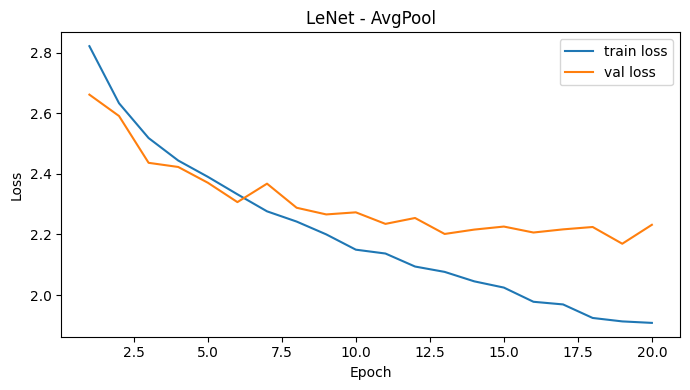

In [12]:
EPOCHS = 20

# Tạo dữ liệu với ảnh 64x64 và augmentation cho tập train
train_ds, val_ds, test_ds, train_loader, val_loader, test_loader = build_dataloaders(
    img_size=64,
    augment=True,
)

# Khởi tạo mô hình LeNet với AvgPool
seed_everything()
lenet_avg = LeNet5(pool="avg")

# Huấn luyện mô hình
lenet_avg, hist_lenet_avg = fit_model(
    lenet_avg,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    lr=1e-3,
)

# Vẽ biểu đồ loss
plot_loss(hist_lenet_avg, "LeNet - AvgPool")

**Nhận xét**

- Train loss giảm đều từ `2.8212` xuống `1.9080`, cho thấy mô hình học tốt trên tập train.
- Validation loss giảm ở giai đoạn đầu nhưng dao động quanh `2.2` ở các epoch sau, nên mức cải thiện trên validation bắt đầu chững lại.
- Macro-F1 tăng từ `0.0928` lên cao nhất `0.3332` ở epoch 19, cho thấy khả năng phân loại được cải thiện nhưng vẫn còn hạn chế.

Ở các epoch cuối, train loss tiếp tục giảm trong khi validation loss không giảm tương ứng, cho thấy dấu hiệu overfitting nhẹ.

Test loss: 2.3972
accuracy           0.2929
precision_macro    0.3037
recall_macro       0.2677
f1_macro           0.2657
dtype: float64

                  precision    recall  f1-score   support

        banh-can     0.1953    0.1369    0.1610       241
        banh-hoi     0.2670    0.4778    0.3426       607
    banh-mi-chao     0.2926    0.3806    0.3308       289
        banh-tet     0.3967    0.1319    0.1979       364
 banh-trang-tron     0.1343    0.0291    0.0479       309
          banh-u     0.4000    0.1136    0.1770       176
        banh-uot     0.2362    0.3893    0.2940       560
       bap-nuong     0.2069    0.0839    0.1194       143
          bo-kho     0.2285    0.3935    0.2891       338
       bo-la-lot     0.3639    0.6245    0.4598       458
       bot-chien     0.2050    0.1196    0.1510       276
           ca-ri     0.2658    0.1228    0.1680       171
    canh-kho-qua     0.5321    0.5138    0.5228       290
   canh-khoai-mo     0.7791    0.6414    0.7036  

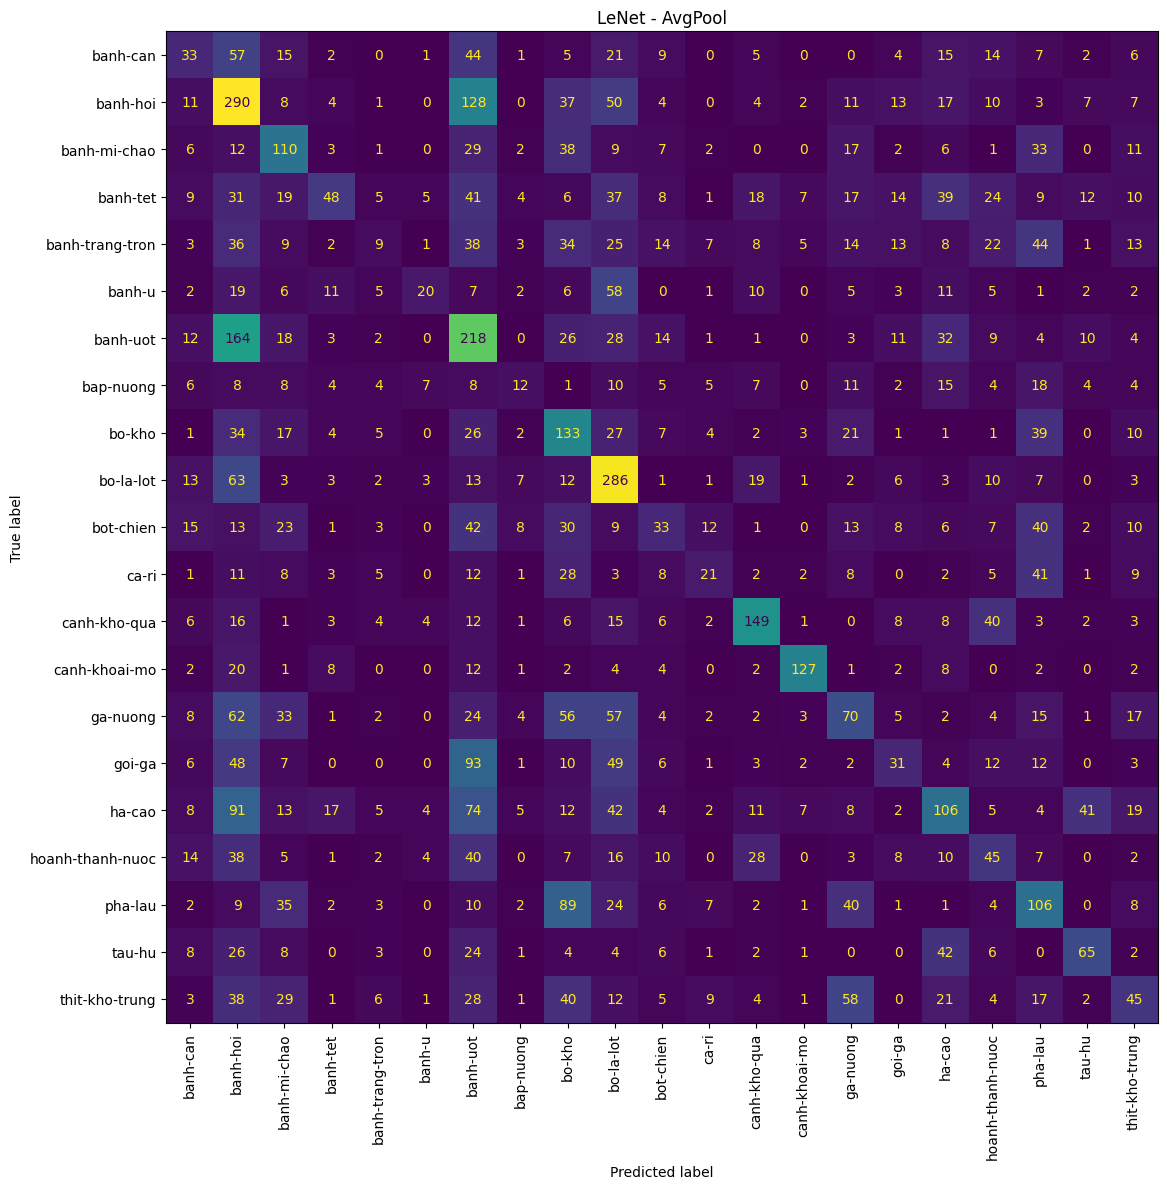

In [13]:
# Đánh giá mô hình trên tập test
metrics_lenet_avg, y_true_avg, y_pred_avg = evaluate_test(
    lenet_avg,
    test_loader,
    train_ds.classes,
)

# Vẽ confusion matrix
plot_confusion(
    y_true_avg,
    y_pred_avg,
    train_ds.classes,
    "LeNet - AvgPool",
)

**Nhận xét**

- LeNet-AvgPool đạt Accuracy `29.29%` và Macro-F1 `0.2657`, cho thấy khả năng phân loại trên 21 lớp còn hạn chế.
- Một số lớp được nhận diện tốt hơn như `canh-khoai-mo`, `canh-kho-qua`, `bo-la-lot`, trong khi nhiều lớp khác vẫn có F1-score thấp.
- Confusion matrix cho thấy mô hình còn nhầm lẫn khá nhiều giữa các lớp, nên khả năng phân biệt đặc trưng của VinaFood21 chưa tốt.

### 3.2. Huấn luyện LeNet — MaxPool

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 01/20 | train_loss=2.8430 | val_loss=2.6911 | val_f1=0.0794 | 84.1s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 02/20 | train_loss=2.6358 | val_loss=2.5250 | val_f1=0.1893 | 82.8s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch 18/20 | train_loss=1.8934 | val_loss=2.2772 | val_f1=0.2926 | 84.6s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | train_loss=1.8576 | val_loss=2.1600 | val_f1=0.3135 | 84.8s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | train_loss=1.8436 | val_loss=2.1153 | val_f1=0.3322 | 84.3s


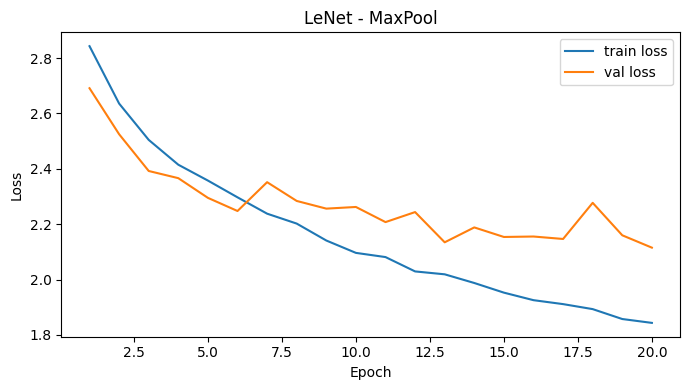

In [14]:
# Khởi tạo mô hình LeNet với MaxPool
seed_everything()
lenet_max = LeNet5(pool="max")

# Huấn luyện mô hình
lenet_max, hist_lenet_max = fit_model(
    lenet_max,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    lr=1e-3,
)

# Vẽ biểu đồ loss
plot_loss(hist_lenet_max, "LeNet - MaxPool")

**Nhận xét**

- Train loss giảm đều từ `2.8430` xuống `1.8436`, cho thấy mô hình học ổn định qua các epoch.
- Validation loss giảm từ `2.6911` xuống `2.1153` nhưng vẫn dao động ở một số epoch, đặc biệt tăng rõ tại epoch 18.
- Macro-F1 tăng từ `0.0794` lên `0.3322` và đạt giá trị cao nhất ở epoch 20, cho thấy chất lượng phân loại trên validation được cải thiện dần.

Test loss: 2.2892
accuracy           0.3251
precision_macro    0.3325
recall_macro       0.3010
f1_macro           0.2986
dtype: float64

                  precision    recall  f1-score   support

        banh-can     0.2290    0.1245    0.1613       241
        banh-hoi     0.3483    0.4349    0.3868       607
    banh-mi-chao     0.3256    0.3875    0.3539       289
        banh-tet     0.3677    0.2253    0.2794       364
 banh-trang-tron     0.3924    0.1003    0.1598       309
          banh-u     0.4167    0.1136    0.1786       176
        banh-uot     0.2678    0.4357    0.3317       560
       bap-nuong     0.1667    0.0839    0.1116       143
          bo-kho     0.2504    0.4408    0.3194       338
       bo-la-lot     0.3821    0.6616    0.4844       458
       bot-chien     0.2199    0.1920    0.2050       276
           ca-ri     0.2162    0.1404    0.1702       171
    canh-kho-qua     0.4577    0.5414    0.4961       290
   canh-khoai-mo     0.7333    0.6667    0.6984  

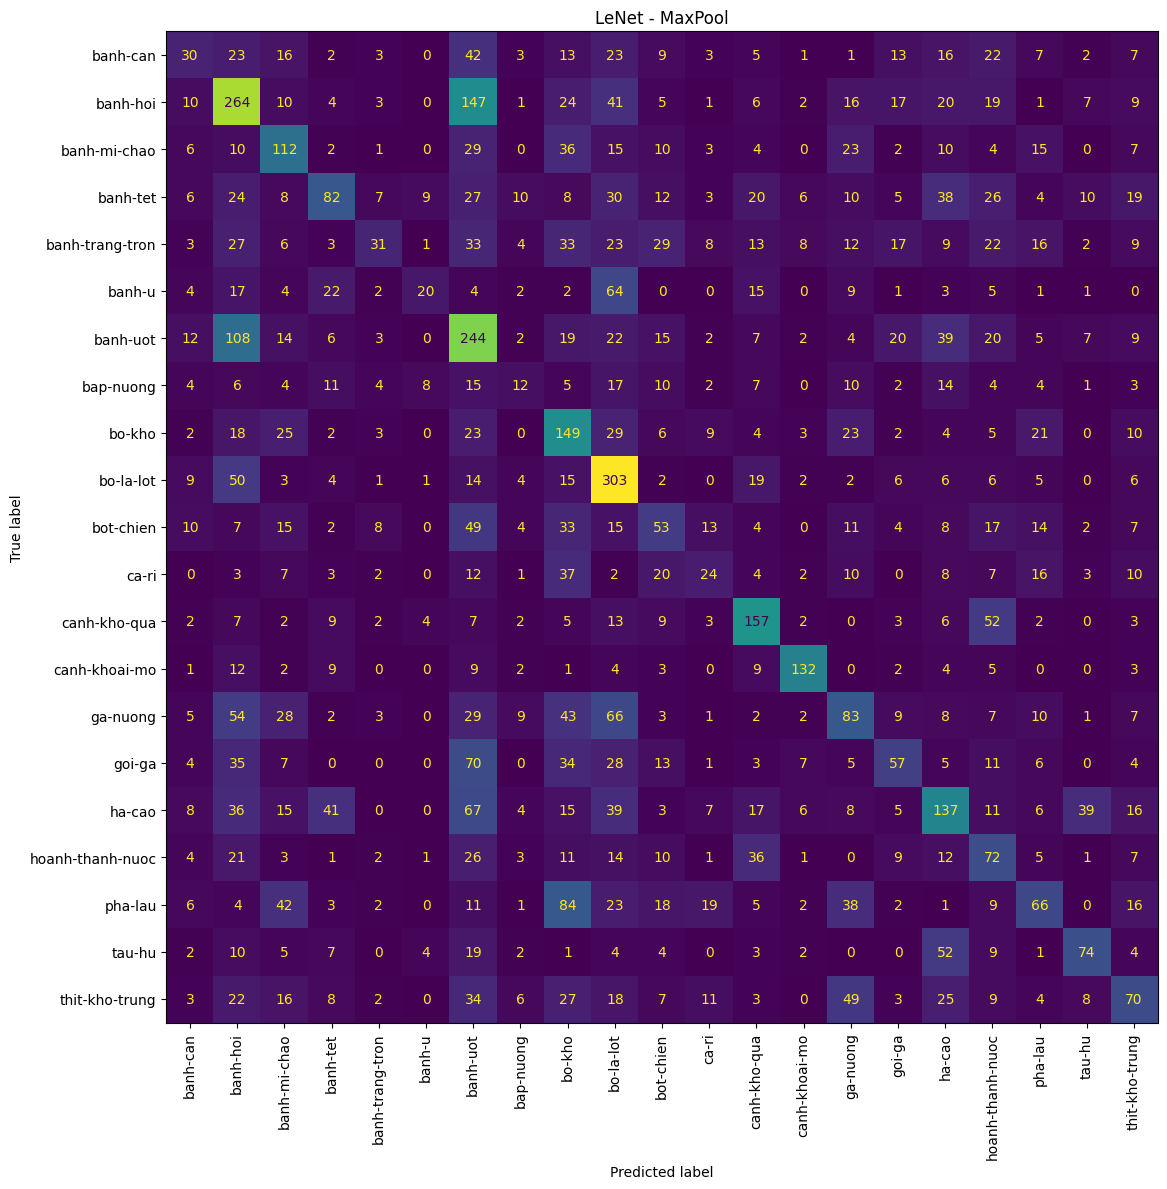

In [15]:
# Đánh giá mô hình LeNet với MaxPool trên tập test
metrics_lenet_max, y_true_max, y_pred_max = evaluate_test(
    lenet_max,
    test_loader,
    train_ds.classes,
)

# Vẽ confusion matrix
plot_confusion(
    y_true_max,
    y_pred_max,
    train_ds.classes,
    "LeNet - MaxPool",
)

**Nhận xét**

- LeNet-MaxPool đạt Accuracy `32.51%` và Macro-F1 `0.2986`, cao hơn kết quả LeNet-AvgPool trước đó (`29.29%`, `0.2657`).
- Một số lớp được nhận diện tốt hơn như `canh-khoai-mo` (`F1 = 0.6984`), `canh-kho-qua` (`0.4961`) và `bo-la-lot` (`0.4844`).
- Confusion matrix vẫn cho thấy nhiều lớp bị nhầm lẫn, nhưng nhìn chung MaxPool cho khả năng phân loại tốt hơn AvgPool trên tập test.

## 3.3 So sánh kết quả giữa AvgPool và MaxPool

In [16]:
# So sánh kết quả giữa AvgPool và MaxPool
compare_pooling = pd.DataFrame([
    {
        "pooling": "AvgPool",
        "parameters": n_params(lenet_avg),
        **metrics_lenet_avg
    },
    {
        "pooling": "MaxPool",
        "parameters": n_params(lenet_max),
        **metrics_lenet_max
    },
])

compare_pooling.round(4)

,pooling,parameters,accuracy,precision_macro,recall_macro,f1_macro
0,AvgPool,339421,0.2929,0.3037,0.2677,0.2657
1,MaxPool,339421,0.3251,0.3325,0.3010,0.2986


**Kết luận**

- Hai mô hình có cùng số tham số (`339,421`), vì vậy chênh lệch kết quả phản ánh trực tiếp ảnh hưởng của phương pháp pooling.
- MaxPool cải thiện đồng thời tất cả các chỉ số: Accuracy tăng **3.22 điểm %**, Precision Macro tăng **0.0288**, Recall Macro tăng **0.0333** và Macro-F1 tăng **0.0329** so với AvgPool.
- Mức tăng ở Recall Macro và Macro-F1 cho thấy MaxPool không chỉ tăng số dự đoán đúng tổng thể mà còn giúp mô hình nhận diện các lớp đồng đều hơn. Vì vậy, với LeNet-5 trên VinaFood21 trong thí nghiệm này, **MaxPool là lựa chọn phù hợp hơn AvgPool**.

# 4. Bài 2 — GoogLeNet

**Yêu cầu**
- Sử dụng cùng dữ liệu với Bài 1, ảnh đầu vào `64×64`.
- Xây dựng mô hình với 3–4 Inception block.
- So sánh với LeNet về số tham số, thời gian mỗi epoch và Macro-F1.

In [17]:
class InceptionBlock(nn.Module):
    """Block Inception của GoogLeNet."""
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()

        # Nhánh 1: Conv 1x1
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1),
            nn.ReLU(),
        )

        # Nhánh 2: Conv 1x1 -> Conv 3x3
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1),
            nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1),
            nn.ReLU(),
        )

        # Nhánh 3: Conv 1x1 -> Conv 5x5
        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1),
            nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2),
            nn.ReLU(),
        )

        # Nhánh 4: MaxPool -> Conv 1x1
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1),
            nn.ReLU(),
        )

         # Tổng số channel sau khi nối 4 nhánh
        self.out_channels = f1 + f3 + f5 + fp

    def forward(self, x):
        x1 = self.b1(x)
        x2 = self.b2(x)
        x3 = self.b3(x)
        x4 = self.b4(x)

        # Nối các nhánh theo chiều channel
        x = torch.cat([x1, x2, x3, x4], dim=1)

        return x

In [18]:
class MiniGoogLeNet(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()

        # Lớp đầu vào cho ảnh 64x64
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)   # 64 -> 32
        )

        # Inception block 1
        self.inc1 = InceptionBlock(32, 16, 16, 24, 4, 8, 8)      # 56 channels
        self.pool1 = nn.MaxPool2d(2, 2)                           # 32 -> 16

        # Inception block 2
        self.inc2 = InceptionBlock(56, 32, 32, 48, 8, 16, 16)    # 112 channels
        self.pool2 = nn.MaxPool2d(2, 2)                           # 16 -> 8

        # Inception block 3
        self.inc3 = InceptionBlock(112, 64, 48, 64, 12, 24, 24)  # 176 channels

        # Global Average Pooling và lớp phân loại
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(176, num_classes)

    def forward(self, x):
        x = self.stem(x)

        x = self.inc1(x)
        x = self.pool1(x)

        x = self.inc2(x)
        x = self.pool2(x)

        x = self.inc3(x)

        x = self.gap(x)
        x = x.flatten(1)
        x = self.fc(x)

        return x

### Kiểm tra số channel của từng Inception block

Theo công thức:

\[
C_{out} = f_1 + f_3 + f_5 + f_p
\]

- Inception 1:
  `16 + 24 + 8 + 8 = 56` channels

- Inception 2:
  `32 + 48 + 16 + 16 = 112` channels

- Inception 3:
  `64 + 64 + 24 + 24 = 176` channels

Hai tham số `f3r` và `f5r` là số channel trung gian sau convolution `1×1`,
không cộng vào output cuối của block.

In [19]:
# Kiểm tra số channel sau mỗi Inception block
google_check = MiniGoogLeNet()
x = torch.randn(2, 3, 64, 64)

with torch.no_grad():
    z = google_check.stem(x)

    z1 = google_check.inc1(z)
    z2 = google_check.inc2(google_check.pool1(z1))
    z3 = google_check.inc3(google_check.pool2(z2))

    logits = google_check(x)

# Tạo bảng số channel sau từng block
channel_table = pd.DataFrame([
    {"block": "Inception 1", "output_channels": z1.shape[1]},
    {"block": "Inception 2", "output_channels": z2.shape[1]},
    {"block": "Inception 3", "output_channels": z3.shape[1]},
])

print(channel_table.to_string(index=False))
print("Kích thước đầu ra:", tuple(logits.shape))
print("Số tham số       :", f"{n_params(google_check):,}")

# Kiểm tra kết quả
assert z1.shape[1] == 56
assert z2.shape[1] == 112
assert z3.shape[1] == 176
assert logits.shape == (2, 21)

      block  output_channels
Inception 1               56
Inception 2              112
Inception 3              176
Kích thước đầu ra: (2, 21)
Số tham số       : 84,117


## 4.1 MiniGoogLeNet

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 01/20 | train_loss=2.9070 | val_loss=2.7910 | val_f1=0.0537 | 84.7s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 02/20 | train_loss=2.6722 | val_loss=2.6058 | val_f1=0.1277 | 85.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch 18/20 | train_loss=1.7682 | val_loss=1.8227 | val_f1=0.4020 | 83.8s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | train_loss=1.7385 | val_loss=1.8762 | val_f1=0.3835 | 84.7s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | train_loss=1.7252 | val_loss=1.8086 | val_f1=0.4129 | 84.0s


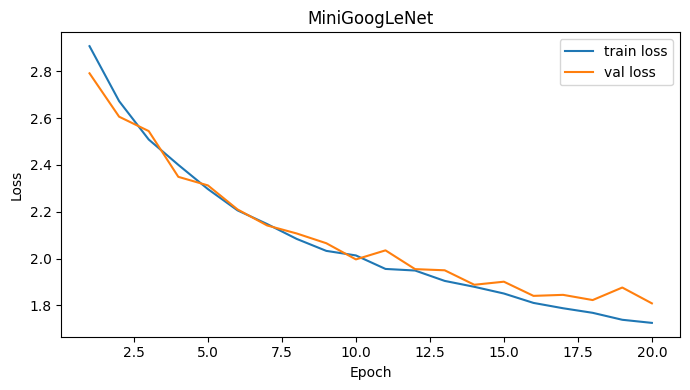

In [20]:
# Khởi tạo mô hình MiniGoogLeNet
seed_everything()
google = MiniGoogLeNet()

# Huấn luyện mô hình
google, hist_google = fit_model(
    google,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    lr=1e-3,
)

# Vẽ biểu đồ loss
plot_loss(hist_google, "MiniGoogLeNet")

**Nhận xét**

- Train loss giảm từ `2.9070` xuống `1.7252`, cho thấy MiniGoogLeNet học ổn định qua các epoch.
- Validation loss cũng giảm rõ rệt từ `2.7910` xuống `1.8086`.
- Macro-F1 tăng từ `0.0537` lên `0.4129`, cho thấy chất lượng phân loại trên tập validation được cải thiện đáng kể.
- Ở epoch cuối, train loss và validation loss vẫn khá gần nhau (`1.7252` và `1.8086`), nên chưa thấy dấu hiệu overfitting rõ rệt.

So với LeNet trước đó, MiniGoogLeNet đạt validation loss thấp hơn và Macro-F1 cao hơn, cho thấy kiến trúc Inception học đặc trưng hiệu quả hơn trên VinaFood21.

Test loss: 2.0468
accuracy           0.3861
precision_macro    0.4140
recall_macro       0.3545
f1_macro           0.3608
dtype: float64

                  precision    recall  f1-score   support

        banh-can     0.2275    0.2407    0.2339       241
        banh-hoi     0.3038    0.7117    0.4258       607
    banh-mi-chao     0.4840    0.3668    0.4173       289
        banh-tet     0.4808    0.3791    0.4240       364
 banh-trang-tron     0.2752    0.1327    0.1790       309
          banh-u     0.4598    0.2273    0.3042       176
        banh-uot     0.3084    0.3393    0.3231       560
       bap-nuong     0.2750    0.0769    0.1202       143
          bo-kho     0.5249    0.4053    0.4574       338
       bo-la-lot     0.4613    0.7424    0.5690       458
       bot-chien     0.3810    0.2029    0.2648       276
           ca-ri     0.4483    0.1520    0.2271       171
    canh-kho-qua     0.4865    0.6207    0.5455       290
   canh-khoai-mo     0.8981    0.7121    0.7944  

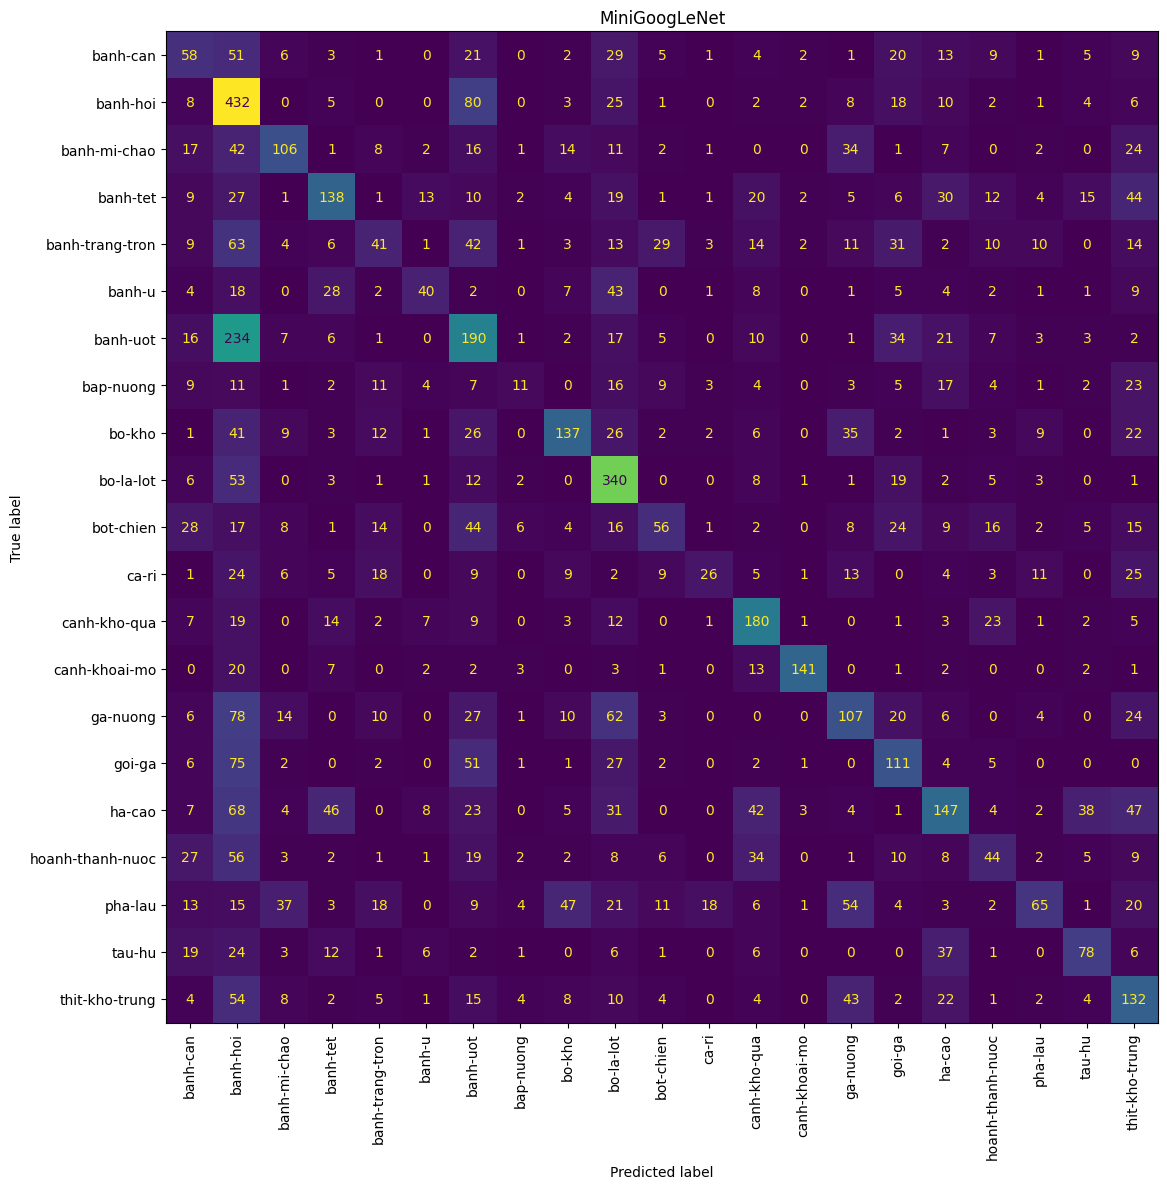

In [21]:
# Đánh giá MiniGoogLeNet trên tập test
metrics_google, y_true_google, y_pred_google = evaluate_test(
    google,
    test_loader,
    train_ds.classes,
)

# Vẽ confusion matrix
plot_confusion(
    y_true_google,
    y_pred_google,
    train_ds.classes,
    "MiniGoogLeNet",
)

**Nhận xét**

- MiniGoogLeNet đạt Accuracy `38.61%` và Macro-F1 `0.3608`, cao hơn rõ rệt so với LeNet-AvgPool (`29.29%`, `0.2657`) và LeNet-MaxPool (`32.51%`, `0.2986`).
- Một số lớp được nhận diện tốt như `canh-khoai-mo` (`F1 = 0.7944`), `bo-la-lot` (`0.5690`) và `canh-kho-qua` (`0.5455`), nhưng một số lớp như `bap-nuong`, `banh-trang-tron` vẫn có F1 thấp.
- Confusion matrix cho thấy mức nhầm lẫn đã giảm so với LeNet, nhưng mô hình vẫn chưa phân loại đồng đều giữa 21 lớp.

## 4.2 So sánh LeNet và GoogLeNet

In [22]:
# So sánh LeNet và GoogLeNet
compare_lenet_google = pd.DataFrame([
    {
        "Model": "LeNet AvgPool",
        "Parameters": n_params(lenet_avg),
        "Sec/Epoch": hist_lenet_avg["seconds"].mean(),
        "Accuracy": metrics_lenet_avg["accuracy"],
        "Macro-F1": metrics_lenet_avg["f1_macro"],
    },
    {
        "Model": "MiniGoogLeNet",
        "Parameters": n_params(google),
        "Sec/Epoch": hist_google["seconds"].mean(),
        "Accuracy": metrics_google["accuracy"],
        "Macro-F1": metrics_google["f1_macro"],
    },
])

compare_lenet_google.round(4)

,Model,Parameters,Sec/Epoch,Accuracy,Macro-F1
0,LeNet AvgPool,339421,110.9475,0.2929,0.2657
1,MiniGoogLeNet,84117,85.1254,0.3861,0.3608


**Kết luận**

- MiniGoogLeNet chỉ có `84,117` tham số, ít hơn khoảng `75.2%` so với LeNet-AvgPool (`339,421` tham số).
- Thời gian trung bình mỗi epoch của MiniGoogLeNet là `85.13s`, nhanh hơn khoảng `25.82s/epoch` so với LeNet (`110.95s`).
- MiniGoogLeNet cũng cho kết quả tốt hơn rõ rệt: Accuracy tăng từ `29.29%` lên `38.61%` (**+9.32 điểm %**) và Macro-F1 tăng từ `0.2657` lên `0.3608` (**+0.0951**).

Như vậy, MiniGoogLeNet vừa gọn hơn, huấn luyện nhanh hơn, vừa cho khả năng phân loại tốt hơn LeNet-AvgPool trên VinaFood21.

# 5. Bài 3* — ResNet-18 từ đầu

- Resize ảnh về `96×96`.
- Xây dựng ResNet-18 với cấu trúc `[2, 2, 2, 2]`.
- Huấn luyện hai trường hợp: không augmentation và có augmentation.
- So sánh train/validation loss và Macro-F1.

In [23]:
class BasicBlock(nn.Module):
    """Khối residual cơ bản của ResNet."""
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()

        # Nhánh chính
        self.conv1 = nn.Conv2d(
            in_ch, out_ch,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_ch)

        self.conv2 = nn.Conv2d(
            out_ch, out_ch,
            kernel_size=3,
            padding=1,
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_ch)

        # Nhánh shortcut
        self.shortcut = nn.Identity()

        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_ch, out_ch,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_ch)
            )

    def forward(self, x):
        # Nhánh chính
        out = self.conv1(x)
        out = self.bn1(out)
        out = torch.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        # Cộng với shortcut
        out = out + self.shortcut(x)
        out = torch.relu(out)

        return out


class ResNet18(nn.Module):
    """ResNet-18 gồm 4 stage, mỗi stage có 2 BasicBlock."""
    def __init__(self, num_classes=21):
        super().__init__()

        # Lớp đầu vào
        self.stem = nn.Sequential(
            nn.Conv2d(
                3, 64,
                kernel_size=7,
                stride=2,
                padding=3,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

        # ResNet-18 có cấu trúc [2, 2, 2, 2]
        self.layer1 = self._stage(64, 64, stride=1)
        self.layer2 = self._stage(64, 128, stride=2)
        self.layer3 = self._stage(128, 256, stride=2)
        self.layer4 = self._stage(256, 512, stride=2)

        # Global Average Pooling và lớp phân loại
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        """Tạo một stage gồm 2 BasicBlock."""
        return nn.Sequential(
            BasicBlock(in_ch, out_ch, stride),
            BasicBlock(out_ch, out_ch, 1)
        )

    def forward(self, x):
        x = self.stem(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.pool(x)
        x = x.flatten(1)
        x = self.fc(x)

        return x

In [24]:
# Kiểm tra output và số tham số của ResNet-18
resnet_check = ResNet18()
dummy = torch.randn(2, 3, 96, 96)

print("Kích thước đầu ra:", tuple(resnet_check(dummy).shape))
print("Số tham số       :", f"{n_params(resnet_check):,}")

assert resnet_check(dummy).shape == (2, 21)
assert n_params(resnet_check) == 11_187_285

Kích thước đầu ra: (2, 21)
Số tham số       : 11,187,285


## 5.1 ResNet 18 - Không sử dụng augmentation

In [25]:
# Tạo dữ liệu ResNet-18 (96x96), không sử dụng augmentation
train_ds_r, val_ds_r, test_ds_r, train_loader_r, val_loader_r, test_loader_r = build_dataloaders(
    img_size=96,
    augment=False,
)

# Khởi tạo ResNet-18
seed_everything()
resnet_plain = ResNet18()

# Huấn luyện mô hình
resnet_plain, hist_resnet_plain = fit_model(
    resnet_plain,
    train_loader_r,
    val_loader_r,
    epochs=20,
    lr=1e-3,
)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 01/20 | train_loss=2.6638 | val_loss=2.5756 | val_f1=0.1286 | 83.7s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 02/20 | train_loss=2.3930 | val_loss=2.2531 | val_f1=0.2476 | 87.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch 18/20 | train_loss=0.0675 | val_loss=2.7736 | val_f1=0.4805 | 85.7s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | train_loss=0.1209 | val_loss=2.7867 | val_f1=0.4928 | 84.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | train_loss=0.0486 | val_loss=3.2942 | val_f1=0.4471 | 84.4s


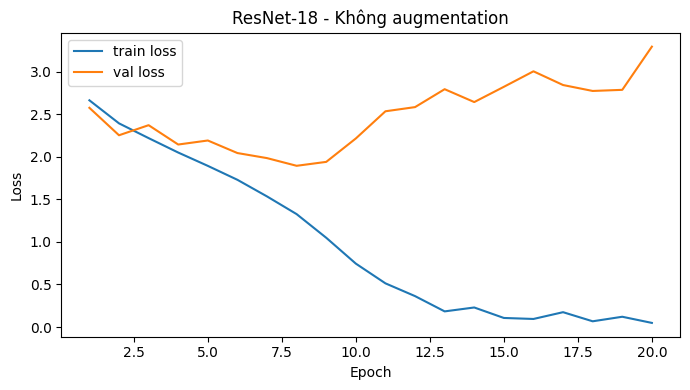

Test loss: 3.8999
accuracy           0.3911
precision_macro    0.3951
recall_macro       0.3746
f1_macro           0.3650
dtype: float64

                  precision    recall  f1-score   support

        banh-can     0.3333    0.2739    0.3007       241
        banh-hoi     0.5450    0.3987    0.4605       607
    banh-mi-chao     0.3024    0.5986    0.4019       289
        banh-tet     0.4008    0.5275    0.4555       364
 banh-trang-tron     0.3158    0.2136    0.2548       309
          banh-u     0.4054    0.1705    0.2400       176
        banh-uot     0.3505    0.3768    0.3632       560
       bap-nuong     0.2404    0.1748    0.2024       143
          bo-kho     0.4050    0.4349    0.4194       338
       bo-la-lot     0.5343    0.6463    0.5850       458
       bot-chien     0.3782    0.2645    0.3113       276
           ca-ri     0.2857    0.1053    0.1538       171
    canh-kho-qua     0.3287    0.7310    0.4535       290
   canh-khoai-mo     0.8880    0.5606    0.6873  

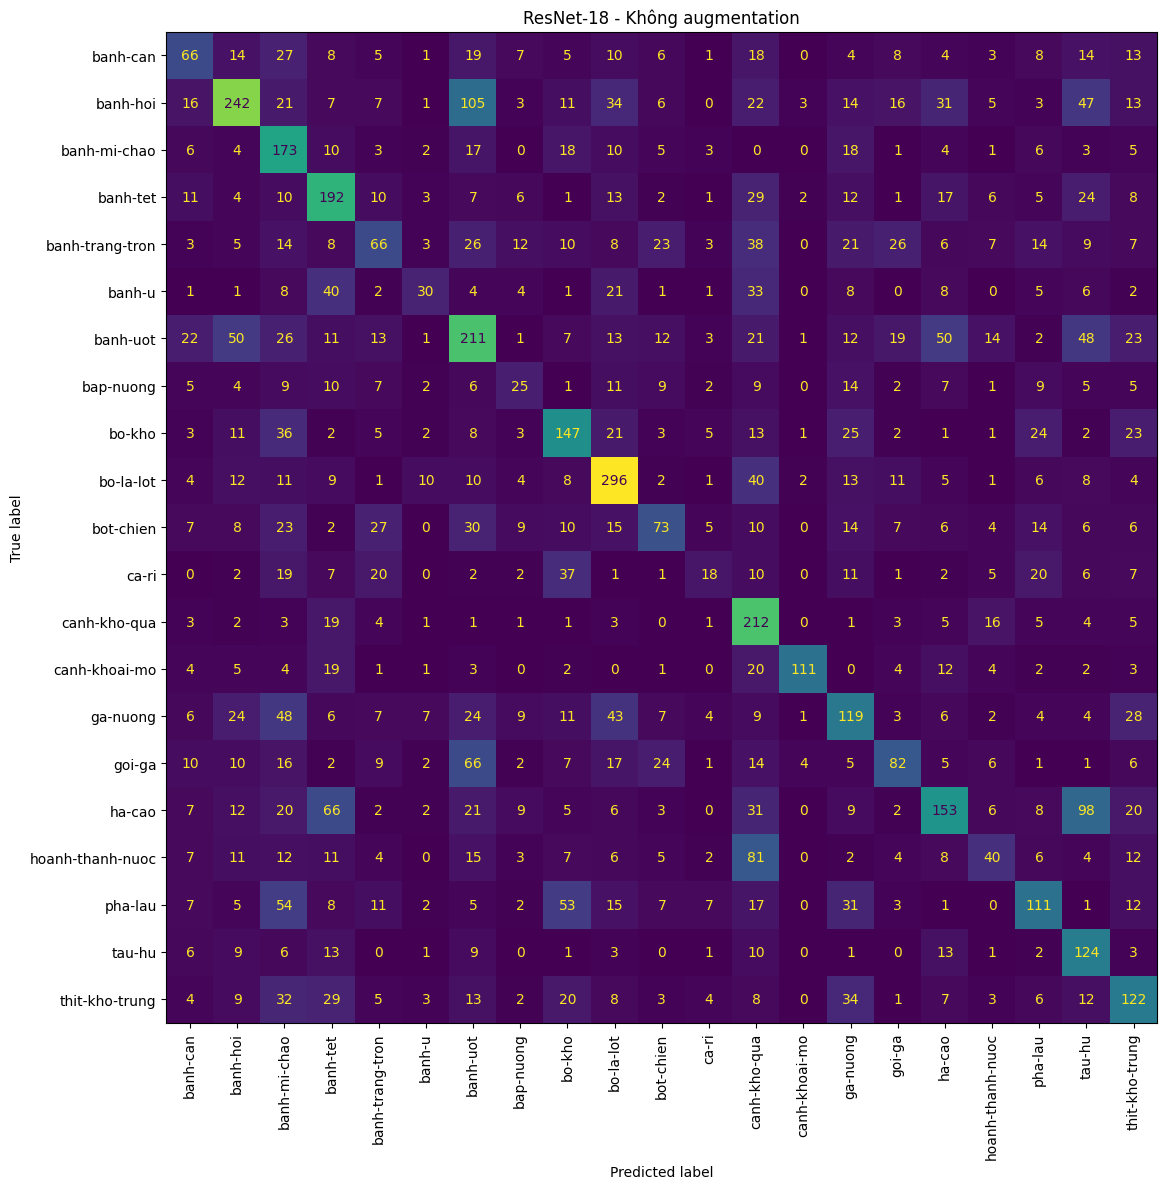

In [26]:
# Vẽ biểu đồ loss
plot_loss(
    hist_resnet_plain,
    "ResNet-18 - Không augmentation"
)

# Đánh giá trên tập test
metrics_resnet_plain, y_true_resnet_plain, y_pred_resnet_plain = evaluate_test(
    resnet_plain,
    test_loader_r,
    train_ds_r.classes,
)

# Vẽ confusion matrix
plot_confusion(
    y_true_resnet_plain,
    y_pred_resnet_plain,
    train_ds_r.classes,
    "ResNet-18 - Không augmentation",
)

**Nhận xét**

- **Quá trình huấn luyện:** Train loss giảm rất mạnh từ `2.6638` xuống `0.0486`, cho thấy mô hình học rất sát dữ liệu train. Tuy nhiên, từ khoảng epoch 9 trở đi, train loss tiếp tục giảm nhanh trong khi validation loss bắt đầu tăng mạnh.
- **Biểu đồ loss:** Validation loss đạt mức thấp nhất khoảng `1.8944` ở epoch 8, sau đó tăng dần và lên `3.2942` ở epoch 20. Khoảng cách giữa train loss và validation loss ngày càng lớn, đây là dấu hiệu overfitting rõ rệt.
- **Macro-F1 trên validation:** F1 tăng từ `0.1286` lên cao nhất `0.4928` ở epoch 19, nhưng dao động và giảm còn `0.4471` ở epoch 20. Điều này cho thấy dù mô hình vẫn cải thiện khả năng phân loại ở một số giai đoạn, hiệu quả validation không ổn định.
- **Kết quả trên test:** Mô hình đạt Accuracy `39.11%` và Macro-F1 `0.3650`, thấp hơn đáng kể so với mức F1 tốt nhất trên validation. Test loss `3.8999` cũng khá cao, cho thấy khả năng tổng quát hóa trên dữ liệu mới còn hạn chế.
- **Ma trận nhầm lẫn:** Một số lớp được nhận diện khá tốt như `canh-khoai-mo`, `bo-la-lot`, `canh-kho-qua`, nhưng nhiều lớp vẫn bị nhầm sang các lớp khác. Điều này cho thấy ResNet-18 học được một số đặc trưng mạnh, nhưng chưa phân biệt ổn định trên toàn bộ 21 lớp.

**Kết luận:** ResNet-18 không augmentation học rất tốt trên train nhưng bị overfitting mạnh. Việc thêm augmentation là cần thiết để giảm sự phụ thuộc vào dữ liệu train và cải thiện khả năng tổng quát hóa.

## 5.2 ResNet 18 - Augmentation

In [27]:
# ResNet-18 có augmentation
train_ds_ra, val_ds_ra, test_ds_ra, train_loader_ra, val_loader_ra, test_loader_ra = build_dataloaders(
    img_size=96,
    augment=True,
)

# Khởi tạo ResNet-18
seed_everything()
resnet_aug = ResNet18()

# Huấn luyện mô hình
resnet_aug, hist_resnet_aug = fit_model(
    resnet_aug,
    train_loader_ra,
    val_loader_ra,
    epochs=20,
    lr=1e-3,
)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 01/20 | train_loss=2.7587 | val_loss=2.5989 | val_f1=0.1604 | 95.5s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 02/20 | train_loss=2.4824 | val_loss=2.3803 | val_f1=0.1969 | 92.7s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch 18/20 | train_loss=1.2628 | val_loss=1.6263 | val_f1=0.5155 | 90.6s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | train_loss=1.2184 | val_loss=1.4849 | val_f1=0.5439 | 92.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | train_loss=1.1308 | val_loss=1.6836 | val_f1=0.5098 | 92.3s


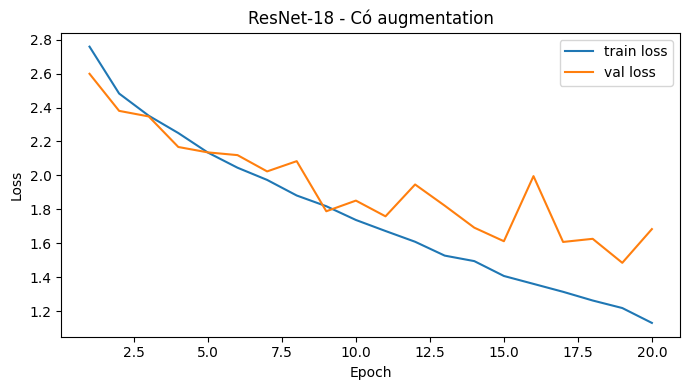

Test loss: 2.0036
accuracy           0.4454
precision_macro    0.4775
recall_macro       0.4465
f1_macro           0.4256
dtype: float64

                  precision    recall  f1-score   support

        banh-can     0.2988    0.5021    0.3746       241
        banh-hoi     0.6382    0.4794    0.5475       607
    banh-mi-chao     0.5103    0.6021    0.5524       289
        banh-tet     0.6507    0.4093    0.5025       364
 banh-trang-tron     0.5781    0.1197    0.1984       309
          banh-u     0.3028    0.6193    0.4067       176
        banh-uot     0.4085    0.3625    0.3841       560
       bap-nuong     0.2459    0.1049    0.1471       143
          bo-kho     0.4910    0.4024    0.4423       338
       bo-la-lot     0.6017    0.6266    0.6139       458
       bot-chien     0.3449    0.3949    0.3682       276
           ca-ri     0.4189    0.1813    0.2531       171
    canh-kho-qua     0.6250    0.7069    0.6634       290
   canh-khoai-mo     0.8639    0.7374    0.7956  

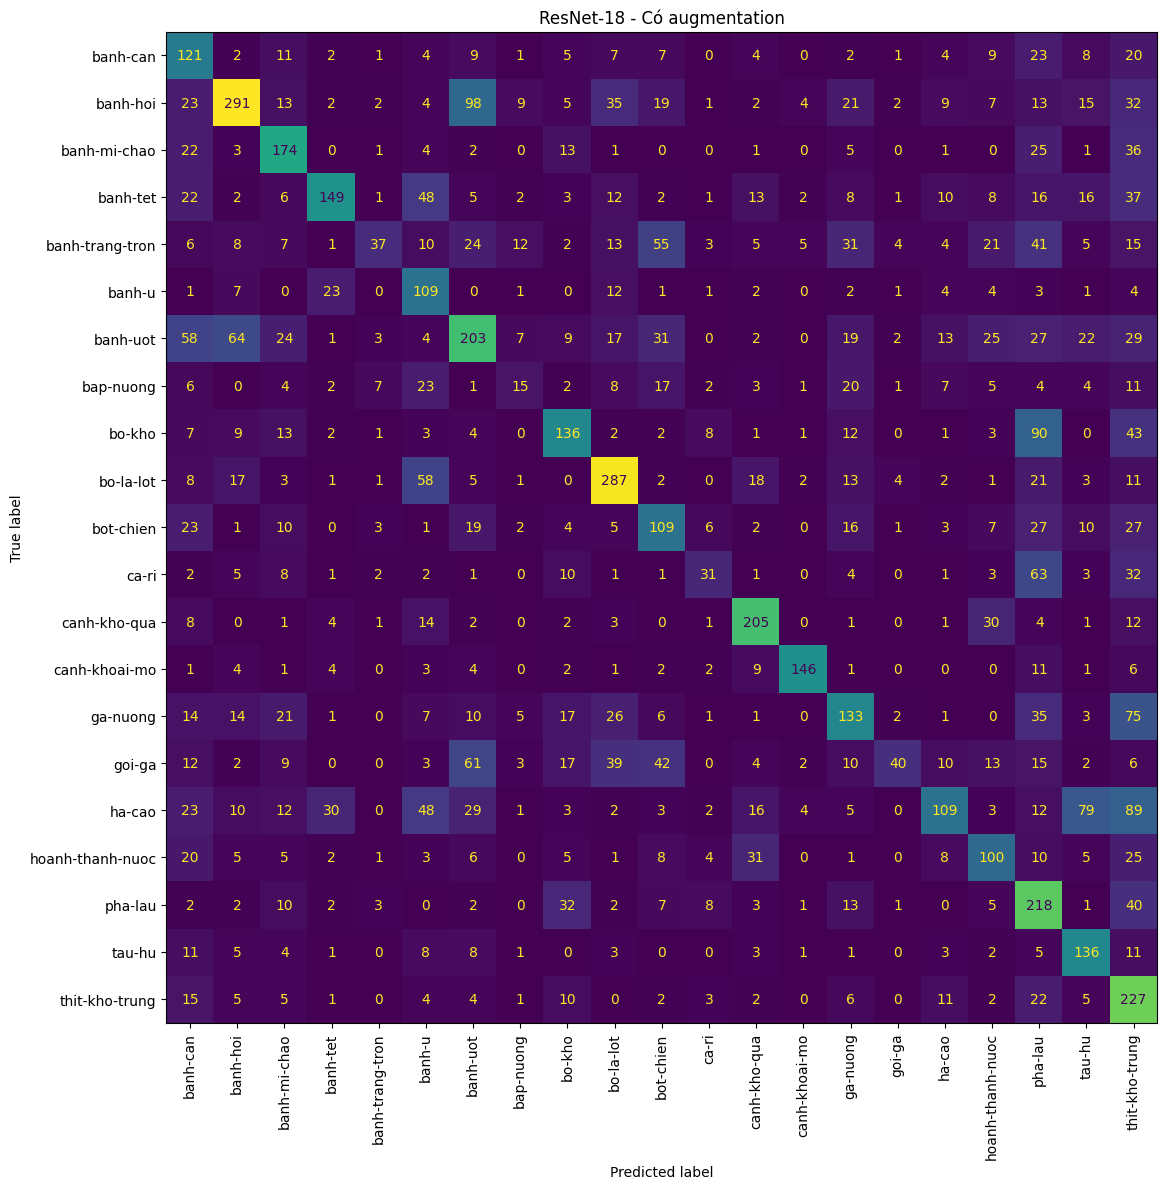

In [28]:
# Vẽ loss của mô hình có augmentation
plot_loss(
    hist_resnet_aug,
    "ResNet-18 - Có augmentation"
)

# Đánh giá đúng mô hình có augmentation trên tập test
metrics_resnet_aug, y_true_resnet_aug, y_pred_resnet_aug = evaluate_test(
    resnet_aug,
    test_loader_ra,
    train_ds_ra.classes,
)

# Confusion matrix
plot_confusion(
    y_true_resnet_aug,
    y_pred_resnet_aug,
    train_ds_ra.classes,
    "ResNet-18 - Có augmentation",
)

**Nhận xét**

- **Quá trình huấn luyện:** Train loss giảm từ `2.7587` xuống `1.1308`, cho thấy mô hình vẫn học tốt nhưng không giảm quá nhanh về gần `0` như trường hợp không augmentation.
- **Biểu đồ loss:** Validation loss nhìn chung giảm từ `2.5989` xuống mức thấp nhất `1.4849` ở epoch 19, dù có dao động ở một số epoch. Khoảng cách giữa train loss và validation loss nhỏ hơn rõ rệt so với mô hình không augmentation, cho thấy overfitting đã được giảm.
- **Macro-F1 trên validation:** F1 tăng từ `0.1604` lên cao nhất `0.5439` ở epoch 19, sau đó giảm còn `0.5098` ở epoch 20. Điều này cho thấy chất lượng phân loại trên validation được cải thiện rõ rệt trong quá trình huấn luyện.
- **Kết quả trên test:** Mô hình đạt Accuracy `44.54%` và Macro-F1 `0.4256`, cao hơn trường hợp không augmentation (`39.11%` và `0.3650`). Test loss cũng giảm từ `3.8999` xuống `2.0036`.
- **Ma trận nhầm lẫn:** Một số lớp được nhận diện khá tốt như `canh-khoai-mo`, `canh-kho-qua`, `bo-la-lot`, nhưng vẫn còn nhiều lớp bị nhầm lẫn và có F1 thấp.

**Kết luận:** Data augmentation giúp ResNet-18 giảm overfitting và cải thiện khả năng tổng quát hóa. So với trường hợp không augmentation, Accuracy tăng `5.43` điểm %, Macro-F1 tăng `0.0606` và test loss giảm đáng kể.

## 5.3 So sánh Augmentation/ No augmentation

In [29]:
# So sánh augmentation / no augmentation
resnet_comparison = pd.DataFrame([
    {
        "Setting": "No augmentation",
        "Parameters": n_params(resnet_plain),
        "Sec/Epoch": hist_resnet_plain["seconds"].mean(),
        "Accuracy": metrics_resnet_plain["accuracy"],
        "Precision": metrics_resnet_plain["precision_macro"],
        "Recall": metrics_resnet_plain["recall_macro"],
        "Macro-F1": metrics_resnet_plain["f1_macro"],
    },
    {
        "Setting": "With augmentation",
        "Parameters": n_params(resnet_aug),
        "Sec/Epoch": hist_resnet_aug["seconds"].mean(),
        "Accuracy": metrics_resnet_aug["accuracy"],
        "Precision": metrics_resnet_aug["precision_macro"],
        "Recall": metrics_resnet_aug["recall_macro"],
        "Macro-F1": metrics_resnet_aug["f1_macro"],
    },
])

resnet_comparison.round(4)

,Setting,Parameters,Sec/Epoch,Accuracy,Precision,Recall,Macro-F1
0,No augmentation,11187285,89.1553,0.3911,0.3951,0.3746,0.3650
1,With augmentation,11187285,91.4639,0.4454,0.4775,0.4465,0.4256


In [30]:
delta_f1_resnet = (
    metrics_resnet_aug["f1_macro"]
    - metrics_resnet_plain["f1_macro"]
)

print(
    f"Chênh lệch Macro-F1 "
    f"(augmentation - no augmentation): "
    f"{delta_f1_resnet:+.4f}"
)

Chênh lệch Macro-F1 (augmentation - no augmentation): +0.0606


**Kết luận**

- Hai mô hình có cùng kiến trúc và cùng số tham số (`11,187,285`), nên chênh lệch kết quả chủ yếu phản ánh tác động của augmentation.
- Augmentation giúp cải thiện đồng thời các chỉ số chính: Accuracy tăng từ `39.11%` lên `44.54%` (**+5.43 điểm %**), Precision Macro tăng `0.0824`, Recall Macro tăng `0.0719` và Macro-F1 tăng `0.0606`. Điều này cho thấy mô hình không chỉ dự đoán đúng nhiều hơn mà còn cải thiện khả năng nhận diện đồng đều giữa các lớp.
- Biểu đồ loss cho thấy khác biệt rõ về khả năng tổng quát hóa: mô hình không augmentation có train loss gần về `0` trong khi validation loss tăng mạnh, còn mô hình có augmentation duy trì khoảng cách train/validation loss nhỏ hơn và ổn định hơn. Vì vậy, augmentation giúp hạn chế hiện tượng ghi nhớ tập train quá mức.
- Chi phí đổi lại khá nhỏ: thời gian trung bình mỗi epoch chỉ tăng từ `89.16s` lên `91.46s` (**+2.31s/epoch**), trong khi hiệu quả trên tập test tăng rõ rệt.

**Kết luận chung:** Với ResNet-18 trên VinaFood21, augmentation là lựa chọn hiệu quả vì giúp giảm overfitting và cải thiện rõ khả năng tổng quát hóa, trong khi chi phí thời gian huấn luyện tăng không đáng kể.

# 6. Bài 4* — ResNet-50 pretrained

- Resize ảnh về `224×224`.
- Sử dụng backbone pretrained `microsoft/resnet-50`.
- Thay classifier bằng `Linear(2048, 21)`.
- Feature extraction: đóng băng backbone, Adam với `lr=1e-3`.
- Fine-tuning: cập nhật toàn bộ mạng, Adam với `lr=1e-4`.

In [31]:
from transformers import ResNetForImageClassification


class PretrainedResNet50(nn.Module):
    """ResNet-50 pretrained với classifier mới cho 21 lớp."""
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()

        # Tải ResNet-50 pretrained
        base = ResNetForImageClassification.from_pretrained(
            "microsoft/resnet-50"
        )

        # Giữ phần backbone và thay classifier mới
        self.backbone = base.resnet
        self.classifier = nn.Linear(2048, num_classes)

        # Đóng băng backbone khi dùng feature extraction
        if freeze_backbone:
            for p in self.backbone.parameters():
                p.requires_grad = False

    def forward(self, x):
        # Lấy đặc trưng từ backbone
        features = self.backbone(x).pooler_output

        # Chuyển về dạng vector
        features = features.flatten(1)

        # Phân loại 21 lớp
        output = self.classifier(features)

        return output

In [32]:
# Tạo DataLoader cho ResNet-50 với ảnh 224x224
train_ds_224, val_ds_224, test_ds_224, train_loader_224, val_loader_224, test_loader_224 = build_dataloaders(
    img_size=224,
    augment=True,
)

# Feature extraction: đóng băng backbone
feature_extractor = PretrainedResNet50(
    num_classes=21,
    freeze_backbone=True,
)

# Fine-tuning: cho phép cập nhật toàn bộ mô hình
fine_tuner = PretrainedResNet50(
    num_classes=21,
    freeze_backbone=False,
)

# Kiểm tra số tham số
print("Feature extraction:")
print("  Tổng tham số       :", f"{n_params(feature_extractor):,}")
print("  Tham số được train :", f"{n_params(feature_extractor, trainable_only=True):,}")

print("\nFine-tuning:")
print("  Tổng tham số       :", f"{n_params(fine_tuner):,}")
print("  Tham số được train :", f"{n_params(fine_tuner, trainable_only=True):,}")

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Feature extraction:
  Tổng tham số       : 23,551,061
  Tham số được train : 43,029

Fine-tuning:
  Tổng tham số       : 23,551,061
  Tham số được train : 23,551,061


## 6.1 ResNet 50 - Feature extraction

In [33]:
# Huấn luyện theo chế độ feature extraction
seed_everything()

feature_extractor, hist_feature = fit_model(
    feature_extractor,
    train_loader_224,
    val_loader_224,
    epochs=20,
    lr=1e-3,
)

# Đánh giá trên tập test
metrics_feature, y_true_feature, y_pred_feature = evaluate_test(
    feature_extractor,
    test_loader_224,
    train_ds_224.classes,
)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 01/20 | train_loss=2.4859 | val_loss=2.2758 | val_f1=0.4266 | 107.1s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 02/20 | train_loss=1.8959 | val_loss=1.9454 | val_f1=0.5188 | 109.2s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch 18/20 | train_loss=0.9228 | val_loss=1.1378 | val_f1=0.6760 | 104.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | train_loss=0.9021 | val_loss=1.1435 | val_f1=0.6844 | 106.3s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | train_loss=0.8682 | val_loss=1.1549 | val_f1=0.6738 | 105.8s
Test loss: 1.3230
accuracy           0.6118
precision_macro    0.6372
recall_macro       0.6176
f1_macro           0.6100
dtype: float64

                  precision    recall  f1-score   support

        banh-can     0.6345    0.6556    0.6449       241
        banh-hoi     0.6570    0.5206    0.5809       607
    banh-mi-chao     0.7029    0.6713    0.6867       289
        banh-tet     0.9326    0.4945    0.6463       364
 banh-trang-tron     0.8239    0.4693    0.5979       309
          banh-u     0.6442    0.7614    0.6979       176
        banh-uot     0.4942    0.4536    0.4730       560
       bap-nuong     0.7069    0.8601    0.7760       143
          bo-kho     0.4273    0.6864    0.5267       338
       bo-la-lot     0.6195    0.7642    0.6843       458
       bot-chien     0.4844    0.6196    0.5437       276
           ca-ri     0.3125    0.0585    0.0985       171
    canh-kho-qua     0.8417    0

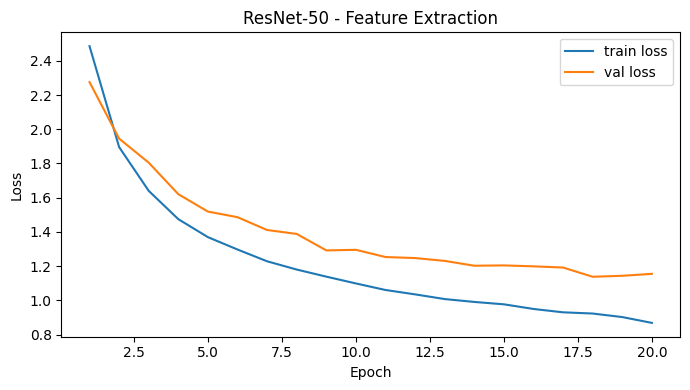

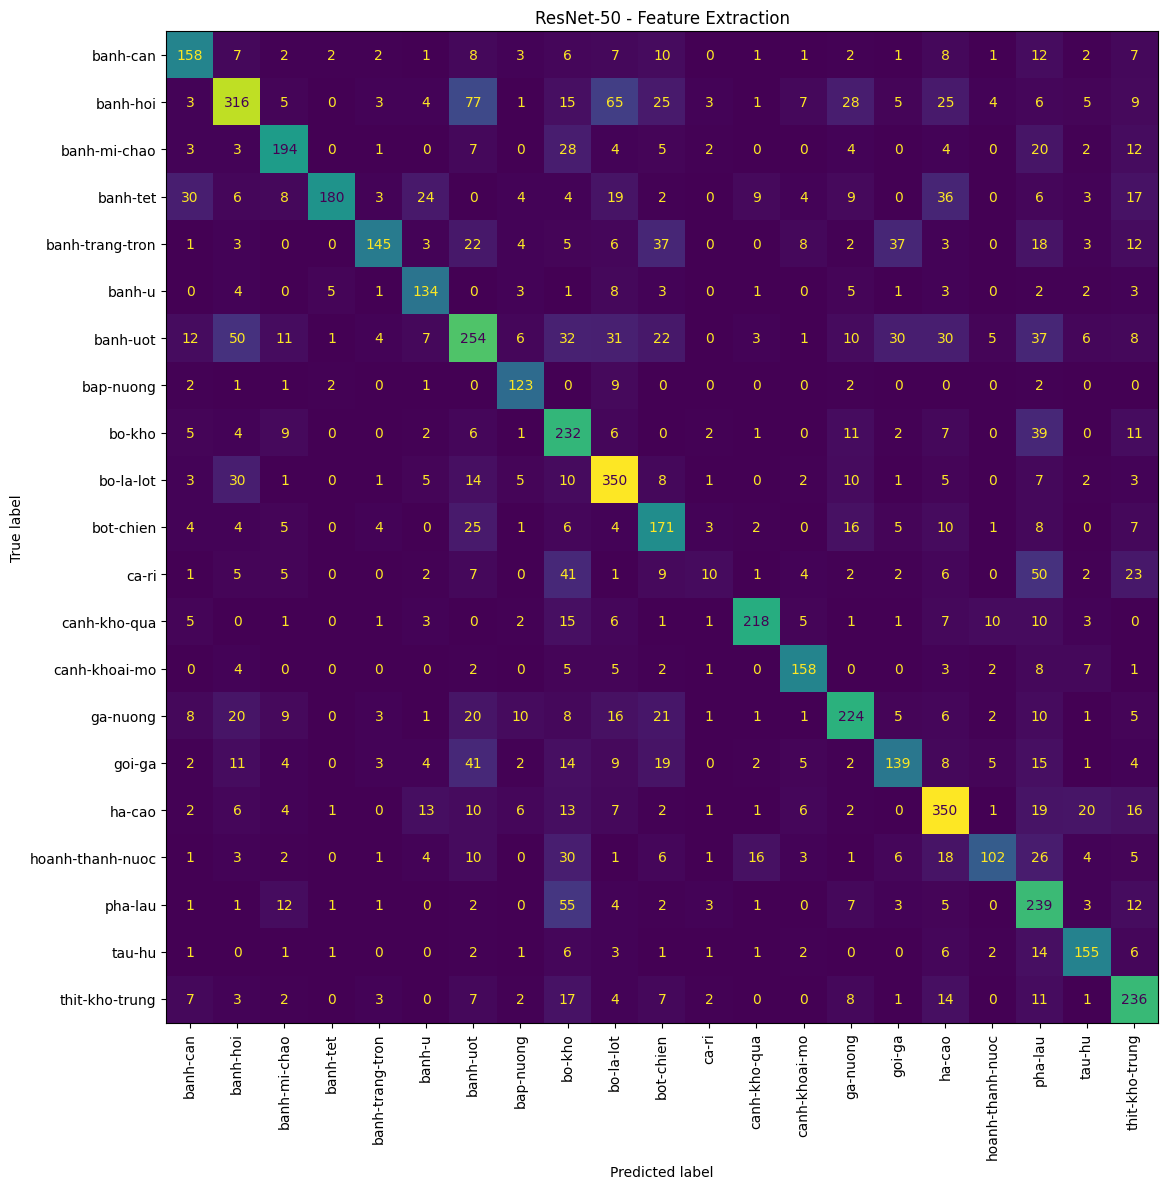

In [34]:
plot_loss(
    hist_feature,
    "ResNet-50 - Feature Extraction"
)

# Vẽ confusion matrix
plot_confusion(
    y_true_feature,
    y_pred_feature,
    train_ds_224.classes,
    "ResNet-50 - Feature Extraction"
)

**Nhận xét**

- **Quá trình huấn luyện:** Train loss giảm từ `2.4859` xuống `0.8682`, cho thấy classifier học được khá tốt trên các đặc trưng từ backbone pretrained.
- **Biểu đồ loss:** Validation loss giảm từ `2.2758` xuống khoảng `1.15` và bắt đầu chững ở các epoch cuối.
- **Macro-F1 trên validation:** tăng từ `0.4266` lên cao nhất `0.6844` ở epoch 19, sau đó còn `0.6738` ở epoch 20.
- **Kết quả trên test:** Accuracy đạt `61.18%`, Macro-F1 đạt `0.6100` và test loss là `1.3230`.
- **Ma trận nhầm lẫn:** một số lớp được nhận diện tốt như `canh-kho-qua`, `canh-khoai-mo`, `bap-nuong`, trong khi `ca-ri` vẫn là lớp khó với F1 khoảng `0.0985`.

**Kết luận:** Feature Extraction tận dụng tốt đặc trưng pretrained và cho kết quả cao hơn các mô hình huấn luyện từ đầu, nhưng backbone cố định vẫn giới hạn khả năng thích nghi với VinaFood21.

## 6.2 ResNet 50 - Fine-tuning

In [35]:
# Huấn luyện theo chế độ fine-tuning
seed_everything()

fine_tuner, hist_finetune = fit_model(
    fine_tuner,
    train_loader_224,
    val_loader_224,
    epochs=20,
    lr=1e-4,
)

# Đánh giá trên tập test
metrics_finetune, y_true_finetune, y_pred_finetune = evaluate_test(
    fine_tuner,
    test_loader_224,
    train_ds_224.classes,
)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 01/20 | train_loss=2.7818 | val_loss=2.4294 | val_f1=0.3034 | 121.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 02/20 | train_loss=1.7845 | val_loss=1.2404 | val_f1=0.6465 | 121.2s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch 18/20 | train_loss=0.0993 | val_loss=0.3836 | val_f1=0.8851 | 121.2s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 19/20 | train_loss=0.0961 | val_loss=0.3795 | val_f1=0.8911 | 121.0s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 20/20 | train_loss=0.0920 | val_loss=0.3947 | val_f1=0.8864 | 121.4s
Test loss: 0.5196
accuracy           0.8589
precision_macro    0.8599
recall_macro       0.8591
f1_macro           0.8581
dtype: float64

                  precision    recall  f1-score   support

        banh-can     0.8296    0.9295    0.8767       241
        banh-hoi     0.9016    0.8600    0.8803       607
    banh-mi-chao     0.9298    0.9170    0.9233       289
        banh-tet     0.9601    0.7940    0.8692       364
 banh-trang-tron     0.9150    0.8706    0.8922       309
          banh-u     0.7850    0.8920    0.8351       176
        banh-uot     0.7780    0.8196    0.7983       560
       bap-nuong     0.9452    0.9650    0.9550       143
          bo-kho     0.8471    0.7870    0.8160       338
       bo-la-lot     0.9032    0.9170    0.9101       458
       bot-chien     0.8333    0.8333    0.8333       276
           ca-ri     0.6199    0.6199    0.6199       171
    canh-kho-qua     0.9286    0

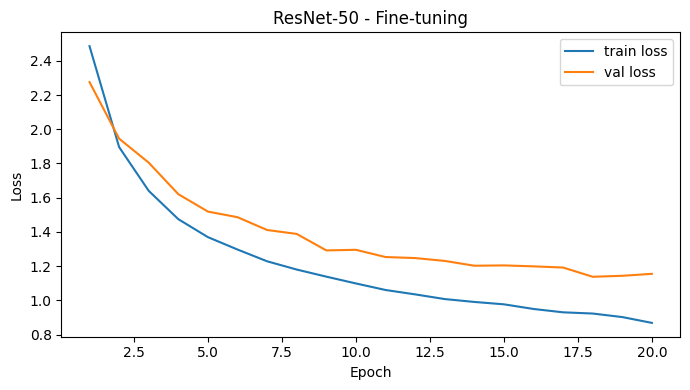

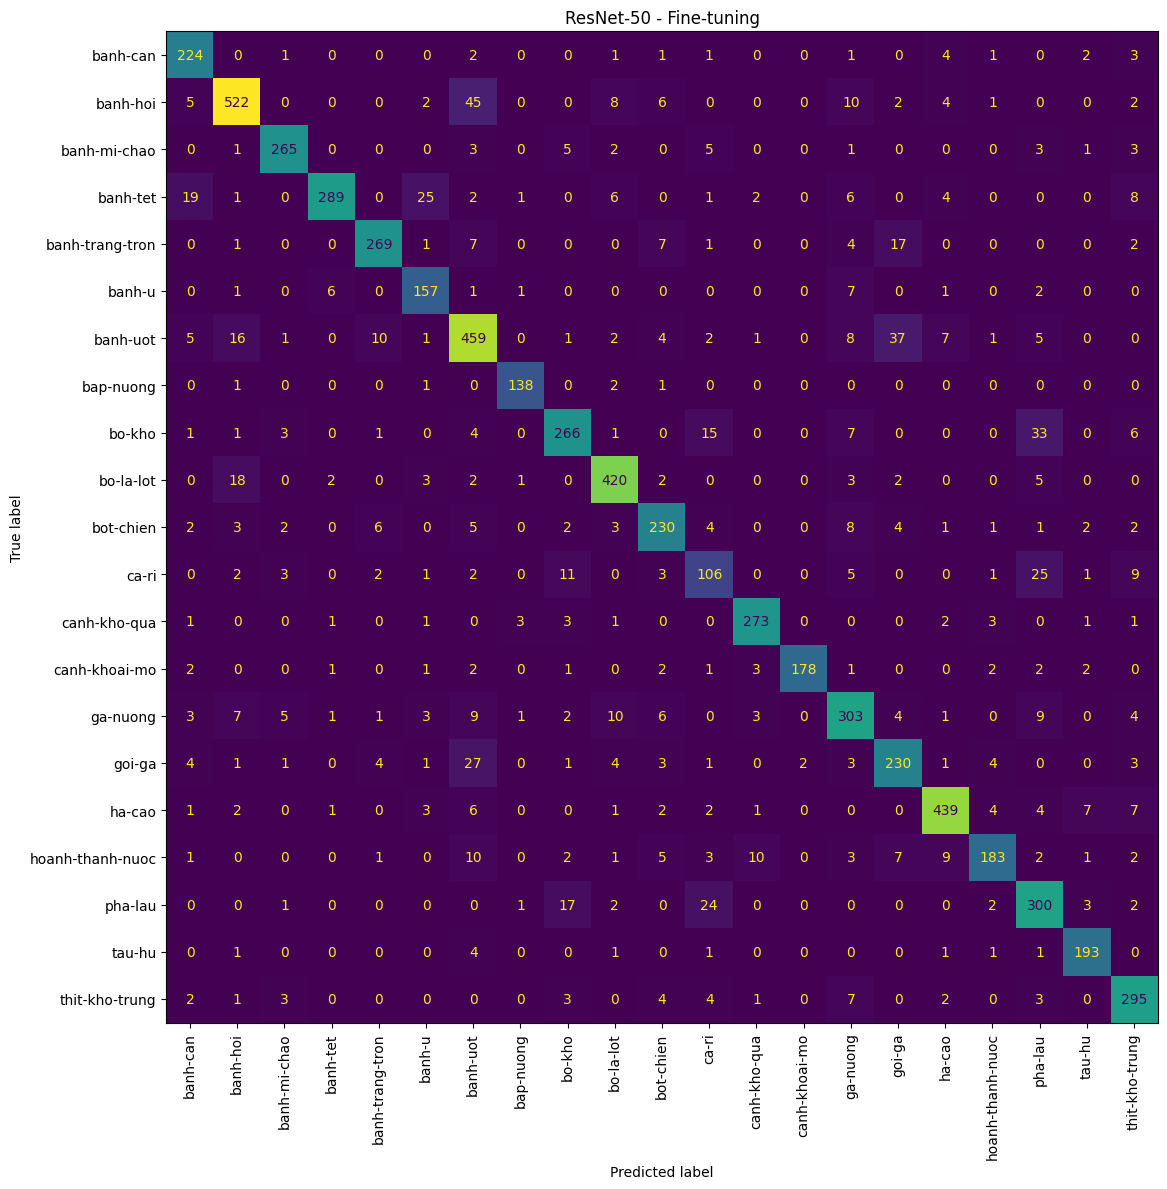

In [ ]:
plot_loss(
    hist_finetune,
    "ResNet-50 - Fine-tuning"
)

# Vẽ confusion matrix
plot_confusion(
    y_true_finetune,
    y_pred_finetune,
    train_ds_224.classes,
    "ResNet-50 - Fine-tuning"
)

**Nhận xét**

- **Quá trình huấn luyện:** Train loss giảm rất mạnh từ `2.7818` xuống `0.0920`, trong khi validation loss giảm từ `2.4294` xuống khoảng `0.38–0.39` ở các epoch cuối. Điều này cho thấy mô hình học rất nhanh và hội tụ tốt sau khi được fine-tune toàn bộ mạng.
- **Biểu đồ loss:** Validation loss giảm mạnh ở các epoch đầu, sau đó gần như ổn định từ khoảng epoch 10 trở đi. Khoảng cách giữa train loss và validation loss có tăng ở cuối nhưng validation loss không tăng mạnh, nên chưa có dấu hiệu overfitting nghiêm trọng.
- **Macro-F1 trên validation:** F1 tăng từ `0.3034` lên cao nhất `0.8911` ở epoch 19, sau đó chỉ giảm nhẹ còn `0.8864` ở epoch 20, cho thấy hiệu quả phân loại cao và khá ổn định.
- **Kết quả trên test:** Mô hình đạt Accuracy `85.89%`, Precision Macro `0.8599`, Recall Macro `0.8591` và Macro-F1 `0.8581`. Các chỉ số khá cân bằng, cho thấy mô hình phân loại tốt trên phần lớn 21 lớp.
- **Ma trận nhầm lẫn:** Đường chéo chính nổi bật rõ rệt, chứng tỏ phần lớn mẫu được dự đoán đúng. Nhiều lớp có F1 rất cao như `bap-nuong`, `canh-kho-qua`, `canh-khoai-mo`, trong khi `ca-ri` vẫn là một trong những lớp khó hơn với F1 khoảng `0.6199`.

**Kết luận:** Fine-tuning giúp ResNet-50 thích nghi rất tốt với VinaFood21, đạt hiệu quả vượt trội so với các mô hình huấn luyện từ đầu và cả feature extraction. Việc cập nhật toàn bộ backbone giúp mô hình học được đặc trưng phù hợp hơn với dữ liệu món ăn, đồng thời vẫn giữ khả năng tổng quát hóa tốt trên tập test.

## 6.3 So sánh Feature Extraction và Fine-tuning

In [37]:
# So sánh Feature Extraction và Fine-tuning
resnet50_comparison = pd.DataFrame([
    {
        "Mode": "Feature extraction",
        "Total params": n_params(feature_extractor),
        "Trainable params": n_params(
            feature_extractor,
            trainable_only=True
        ),
        "Sec/Epoch": hist_feature["seconds"].mean(),
        "Accuracy": metrics_feature["accuracy"],
        "Precision": metrics_feature["precision_macro"],
        "Recall": metrics_feature["recall_macro"],
        "Macro-F1": metrics_feature["f1_macro"],
    },
    {
        "Mode": "Fine-tuning",
        "Total params": n_params(fine_tuner),
        "Trainable params": n_params(
            fine_tuner,
            trainable_only=True
        ),
        "Sec/Epoch": hist_finetune["seconds"].mean(),
        "Accuracy": metrics_finetune["accuracy"],
        "Precision": metrics_finetune["precision_macro"],
        "Recall": metrics_finetune["recall_macro"],
        "Macro-F1": metrics_finetune["f1_macro"],
    },
])

resnet50_comparison.round(4)

,Mode,Total params,Trainable params,Sec/Epoch,Accuracy,Precision,Recall,Macro-F1
0,Feature extraction,23551061,43029,105.5630,0.6118,0.6372,0.6176,0.6100
1,Fine-tuning,23551061,23551061,121.1534,0.8589,0.8599,0.8591,0.8581


In [38]:
delta_f1_resnet50 = (
    metrics_finetune["f1_macro"]
    - metrics_feature["f1_macro"]
)

print(
    f"Chênh lệch Macro-F1 "
    f"(fine-tuning - feature extraction): "
    f"{delta_f1_resnet50:+.4f}"
)

Chênh lệch Macro-F1 (fine-tuning - feature extraction): +0.2481


**Kết luận**

- Feature Extraction và Fine-tuning đều sử dụng cùng kiến trúc ResNet-50 với tổng cộng `23,551,061` tham số, nhưng Feature Extraction chỉ cập nhật `43,029` tham số, trong khi Fine-tuning tối ưu toàn bộ mạng.
- Fine-tuning cải thiện rõ rệt hiệu năng: Accuracy tăng từ `61.18%` lên `85.89%` (**+24.71 điểm %**), Precision Macro tăng `0.2227`, Recall Macro tăng `0.2415` và Macro-F1 tăng `0.2481`.
- Thời gian huấn luyện chỉ tăng từ `105.56s` lên `121.15s` mỗi epoch (**+15.59s/epoch**), trong khi mức cải thiện về kết quả là rất lớn.

**Kết luận chung:** Fine-tuning cho hiệu quả vượt trội trên VinaFood21, cho thấy việc cập nhật toàn bộ backbone giúp ResNet-50 thích nghi tốt hơn với dữ liệu và mang lại mức cải thiện đáng kể so với Feature Extraction.

# 7. Tổng hợp kết quả



In [39]:
rows = [
    {
        "Model": "LeNet",
        "Setting": "AvgPool",
        "Resize": "64x64",
        "Parameters": n_params(lenet_avg),
        "Sec/Epoch": hist_lenet_avg["seconds"].mean(),
        "Accuracy": metrics_lenet_avg["accuracy"],
        "Macro-F1": metrics_lenet_avg["f1_macro"],
    },
    {
        "Model": "LeNet",
        "Setting": "MaxPool",
        "Resize": "64x64",
        "Parameters": n_params(lenet_max),
        "Sec/Epoch": hist_lenet_max["seconds"].mean(),
        "Accuracy": metrics_lenet_max["accuracy"],
        "Macro-F1": metrics_lenet_max["f1_macro"],
    },
    {
        "Model": "MiniGoogLeNet",
        "Setting": "3 Inception blocks",
        "Resize": "64x64",
        "Parameters": n_params(google),
        "Sec/Epoch": hist_google["seconds"].mean(),
        "Accuracy": metrics_google["accuracy"],
        "Macro-F1": metrics_google["f1_macro"],
    },
    {
        "Model": "ResNet-18",
        "Setting": "No augmentation",
        "Resize": "96x96",
        "Parameters": n_params(resnet_plain),
        "Sec/Epoch": hist_resnet_plain["seconds"].mean(),
        "Accuracy": metrics_resnet_plain["accuracy"],
        "Macro-F1": metrics_resnet_plain["f1_macro"],
    },
    {
        "Model": "ResNet-18",
        "Setting": "Augmentation",
        "Resize": "96x96",
        "Parameters": n_params(resnet_aug),
        "Sec/Epoch": hist_resnet_aug["seconds"].mean(),
        "Accuracy": metrics_resnet_aug["accuracy"],
        "Macro-F1": metrics_resnet_aug["f1_macro"],
    },
    {
        "Model": "ResNet-50 pretrained",
        "Setting": "Feature extraction",
        "Resize": "224x224",
        "Parameters": n_params(feature_extractor),
        "Sec/Epoch": hist_feature["seconds"].mean(),
        "Accuracy": metrics_feature["accuracy"],
        "Macro-F1": metrics_feature["f1_macro"],
    },
    {
        "Model": "ResNet-50 pretrained",
        "Setting": "Fine-tuning",
        "Resize": "224x224",
        "Parameters": n_params(fine_tuner),
        "Sec/Epoch": hist_finetune["seconds"].mean(),
        "Accuracy": metrics_finetune["accuracy"],
        "Macro-F1": metrics_finetune["f1_macro"],
    },
]

summary = pd.DataFrame(rows)

summary.round(4)

,Model,Setting,Resize,Parameters,Sec/Epoch,Accuracy,Macro-F1
0,LeNet,AvgPool,64x64,339421,110.9475,0.2929,0.2657
1,LeNet,MaxPool,64x64,339421,84.0710,0.3251,0.2986
2,MiniGoogLeNet,3 Inception blocks,64x64,84117,85.1254,0.3861,0.3608
3,ResNet-18,No augmentation,96x96,11187285,89.1553,0.3911,0.3650
4,ResNet-18,Augmentation,96x96,11187285,91.4639,0.4454,0.4256
5,ResNet-50 pretrained,Feature extraction,224x224,23551061,105.5630,0.6118,0.6100
6,ResNet-50 pretrained,Fine-tuning,224x224,23551061,121.1534,0.8589,0.8581


## Kết luận chung

- **LeNet:** MaxPool cho kết quả tốt hơn AvgPool, với Accuracy tăng từ `29.29%` lên `32.51%` và Macro-F1 tăng từ `0.2657` lên `0.2986`. Điều này cho thấy MaxPool phù hợp hơn với LeNet trên VinaFood21 trong thí nghiệm này.

- **MiniGoogLeNet:** So với LeNet-AvgPool, MiniGoogLeNet có ít tham số hơn đáng kể (`84,117` so với `339,421`) nhưng đạt Accuracy `38.61%` và Macro-F1 `0.3608`, cao hơn LeNet. Kết quả cho thấy kiến trúc Inception khai thác đặc trưng hiệu quả hơn dù mô hình nhỏ hơn.

- **Các lớp dễ nhầm:** Qua các confusion matrix, những lớp như `ca-ri`, `bap-nuong`, `banh-trang-tron` thường có F1-score thấp ở các mô hình huấn luyện từ đầu. Ngược lại, `canh-khoai-mo`, `canh-kho-qua` và `bo-la-lot` thường được nhận diện tốt hơn.

- **ResNet-18 và augmentation:** Khi không augmentation, train loss giảm gần về `0` trong khi validation loss tăng mạnh, cho thấy overfitting rõ rệt. Khi thêm augmentation, Accuracy tăng từ `39.11%` lên `44.54%` và Macro-F1 tăng từ `0.3650` lên `0.4256`, đồng thời khoảng cách giữa train loss và validation loss được thu hẹp. Điều này cho thấy augmentation giúp giảm overfitting và cải thiện khả năng tổng quát hóa.

- **ResNet-50 pretrained:** ResNet-18 tốt nhất khi huấn luyện từ đầu đạt Accuracy `44.54%` và Macro-F1 `0.4256`, trong khi ResNet-50 Feature Extraction đạt `61.18%` và `0.6100`; Fine-tuning tiếp tục tăng lên `85.89%` và `0.8581`. Kết quả cho thấy cấu hình pretrained mang lại lợi thế lớn, còn fine-tuning toàn bộ backbone giúp mô hình thích nghi tốt hơn với đặc trưng của VinaFood21.

**Kết luận cuối:** Kết quả cho thấy hiệu quả phân loại phụ thuộc rõ vào kiến trúc, augmentation và cách tận dụng pretrained weights. Trong toàn bộ thí nghiệm, **ResNet-50 Fine-tuning cho kết quả tốt nhất với Accuracy `85.89%` và Macro-F1 `0.8581`**, còn augmentation là yếu tố quan trọng giúp các mô hình huấn luyện từ đầu hạn chế overfitting và cải thiện khả năng tổng quát hóa.